<a href="https://colab.research.google.com/github/jimqu06/Triton-NeuroTech/blob/main/Copy_of_Workday2_CNN_and_FA_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workday 2: Inside a CNN, then feedback alignment
**Triton NeuroTech research project · Saturday, Nov 7**

Today you will:
1. **Look inside a CNN**: see the filters it learned and what they do to a digit.
2. **Build feedback alignment (FA)** by filling in one line of code.
3. **Race**: train the most accurate FA network.

Run the cells top to bottom with **Shift + Enter**. A GPU is nice but not needed (in Colab: *Runtime > Change runtime type > T4 GPU*).

## Setup

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Running on', device)

Running on cpu


In [2]:
# Download MNIST and keep it all in memory (it is small), so training is fast.
train_set = datasets.MNIST('data', train=True, download=True)
test_set = datasets.MNIST('data', train=False, download=True)

def prep(ds):
    x = (ds.data.float() / 255 - 0.1307) / 0.3081   # scale pixels, then standardize
    return x.unsqueeze(1).to(device), ds.targets.to(device)   # x: (N, 1, 28, 28)

x_train, y_train = prep(train_set)
x_test, y_test = prep(test_set)
print('train:', tuple(x_train.shape), ' test:', tuple(x_test.shape))

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.40MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.83MB/s]


train: (60000, 1, 28, 28)  test: (10000, 1, 28, 28)


In [3]:
def batches(x, y, batch_size, shuffle=True):
    """Yield (images, labels) mini-batches."""
    order = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        idx = order[i:i + batch_size]
        yield x[idx], y[idx]


@torch.no_grad()
def accuracy(model, x, y):
    model.eval()
    correct = sum((model(xb).argmax(1) == yb).sum().item() for xb, yb in batches(x, y, 1000, shuffle=False))
    model.train()
    return correct / len(x)


def train(model, epochs=3, lr=1e-3, optimizer='adam', batch_size=128, callback=None):
    """Plain PyTorch training loop. Works for any model: CNN, BP MLP or FA MLP."""
    model.to(device)
    if optimizer == 'adam':
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    history = {'step': [], 'loss': [], 'test_acc': []}
    step, recent = 0, []
    for epoch in range(epochs):
        for xb, yb in batches(x_train, y_train, batch_size):
            loss = F.cross_entropy(model(xb), yb)   # 1. forward pass + how wrong we were
            opt.zero_grad()
            loss.backward()                          # 2. backward pass: BP or FA happens HERE
            opt.step()                               # 3. nudge the weights
            step += 1
            recent.append(loss.item())
            if step % 50 == 0:                       # log the average loss of the last 50 steps
                history['step'].append(step)
                history['loss'].append(sum(recent) / len(recent))
                recent = []
                if callback:
                    callback(step)
        acc = accuracy(model, x_test, y_test)
        history['test_acc'].append(acc)
        print(f'epoch {epoch + 1}: test accuracy {acc:.2%}')
    return history

## Part 1: Look inside a CNN

A CNN's first layer is a set of small **filters**. Each filter slides over the image, just like on the handout, and makes a **feature map**. The map is bright wherever that part of the image matches the filter's pattern.

### 1a. A filter you design
This is the handout, done by the computer: a vertical-edge filter slid over a real digit.

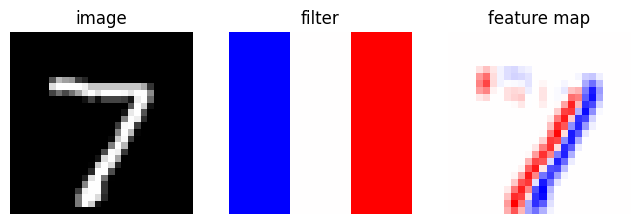

In [4]:
digit = x_test[0, 0].cpu()                    # one test image, 28 x 28
edge = torch.tensor([[-1., 0., 1.],
                     [-1., 0., 1.],
                     [-1., 0., 1.]])          # vertical-edge filter, like the handout
fmap = F.conv2d(digit[None, None], edge[None, None])[0, 0]

fig, ax = plt.subplots(1, 3, figsize=(8, 3))
ax[0].imshow(digit, cmap='gray'); ax[0].set_title('image')
ax[1].imshow(edge, cmap='bwr', vmin=-1, vmax=1); ax[1].set_title('filter')
v = fmap.abs().max()
ax[2].imshow(fmap, cmap='bwr', vmin=-v, vmax=v); ax[2].set_title('feature map')
for a in ax: a.axis('off')
plt.show()

**Look:** red where the image goes dark-to-bright from left to right, blue where it goes bright-to-dark. Flat areas stay white (zero).

### 1b. A small CNN, line by line
Same idea as your homework CNN, written in plain PyTorch.

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=5, padding=2)    # 8 filters, each 5x5, on the 1-channel image
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5, padding=2)   # 16 filters that read conv1's 8 maps
        self.fc = nn.Linear(16 * 7 * 7, 10)                        # 10 scores, one per digit

    def forward(self, x):                                # x: (batch, 1, 28, 28)
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)       # -> (batch, 8, 14, 14)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)       # -> (batch, 16, 7, 7)
        return self.fc(x.flatten(1))                     # -> (batch, 10)


torch.manual_seed(0)
cnn = SmallCNN()
cnn_history = train(cnn, epochs=1)   # one pass over the training set is plenty for MNIST

epoch 1: test accuracy 97.53%


### 1c. What did it learn?
The helper below plots the CNN's first-layer filters and the feature map each one makes for one digit.

In [6]:
import math
import torch, torch.nn as nn
import matplotlib.pyplot as plt


def show_filters_and_feature_maps(model, image, conv_layer=None, after_relu=True, max_filters=16):
    """Plot a trained CNN's filters and the feature maps they make for one image.

    model:      a trained PyTorch CNN, or a trained skorch NeuralNetClassifier
                (skorch keeps the PyTorch model in net.module_, which is used automatically).
    image:      ONE image, scaled exactly the way the model saw images in training.
                Shape (28, 28), (1, 28, 28) or (1, 1, 28, 28); a tensor or a numpy array.
    conv_layer: which nn.Conv2d to look at. Default: the first conv layer.
    after_relu: show feature maps after ReLU (negative values set to 0), which is
                what the next layer actually receives.
    max_filters: show at most this many filters (and their maps).

    Filter i (top rows) and the feature map it makes (bottom rows) sit in the same column.
    Filters use red for positive weights and blue for negative weights.
    """
    net = getattr(model, 'module_', model)
    if conv_layer is None:
        conv_layer = next((m for m in net.modules() if isinstance(m, nn.Conv2d)), None)
        if conv_layer is None:
            raise ValueError('This model has no nn.Conv2d layer, so there are no filters to show.')
    device = next(net.parameters()).device

    img = torch.as_tensor(image, dtype=torch.float32)
    while img.dim() < 4:
        img = img.unsqueeze(0)
    img = img.to(device)

    captured = {}
    hook = conv_layer.register_forward_hook(lambda mod, inp, out: captured.update(maps=out.detach()))
    was_training = net.training
    net.eval()
    try:
        with torch.no_grad():
            net(img)
    finally:
        hook.remove()
        net.train(was_training)

    maps = captured['maps'][0].cpu()
    if after_relu:
        maps = maps.clamp(min=0)
    w = conv_layer.weight.detach().cpu()
    filters = w[:, 0] if w.shape[1] == 1 else w.mean(dim=1)

    n = min(max_filters, filters.shape[0])
    cols = min(8, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(1 + 2 * rows, cols, figsize=(1.6 * cols, 1.7 * (1 + 2 * rows)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')

    axes[0, 0].imshow(img[0, 0].cpu(), cmap='gray')
    axes[0, 0].set_title('input', fontsize=9)
    fig.suptitle(f'{n} filters ({w.shape[2]}x{w.shape[3]}), red = positive weight, blue = negative. '
                 f'Filter i makes map i.', fontsize=9)

    for i in range(n):
        r, c = divmod(i, cols)
        v = filters[i].abs().max().item() or 1.0
        fa = axes[1 + r, c]
        fa.imshow(filters[i], cmap='bwr', vmin=-v, vmax=v)
        fa.set_title(f'filter {i}', fontsize=8)
        ma = axes[1 + rows + r, c]
        ma.imshow(maps[i], cmap='viridis')
        ma.set_title(f'map {i}', fontsize=8)

    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    return filters[:n], maps[:n]

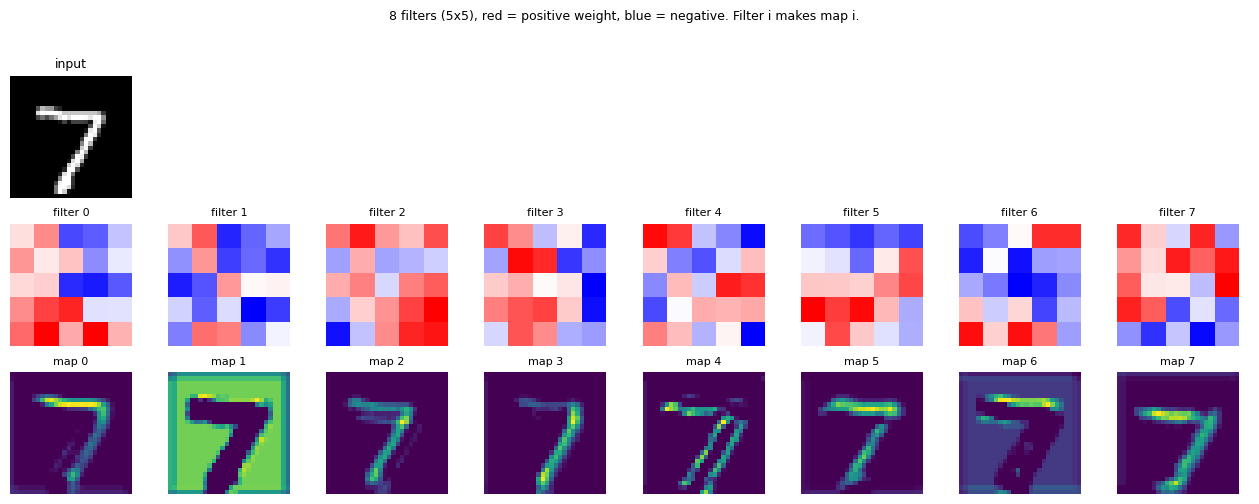

In [7]:
_ = show_filters_and_feature_maps(cnn, x_test[0])

**Discuss with your partner:**
- Which filters look like edge detectors (a red stripe next to a blue stripe)?
- Find a map that lights up only on horizontal strokes. Which filter made it?
- Try another digit: change `x_test[0]` to `x_test[7]`.

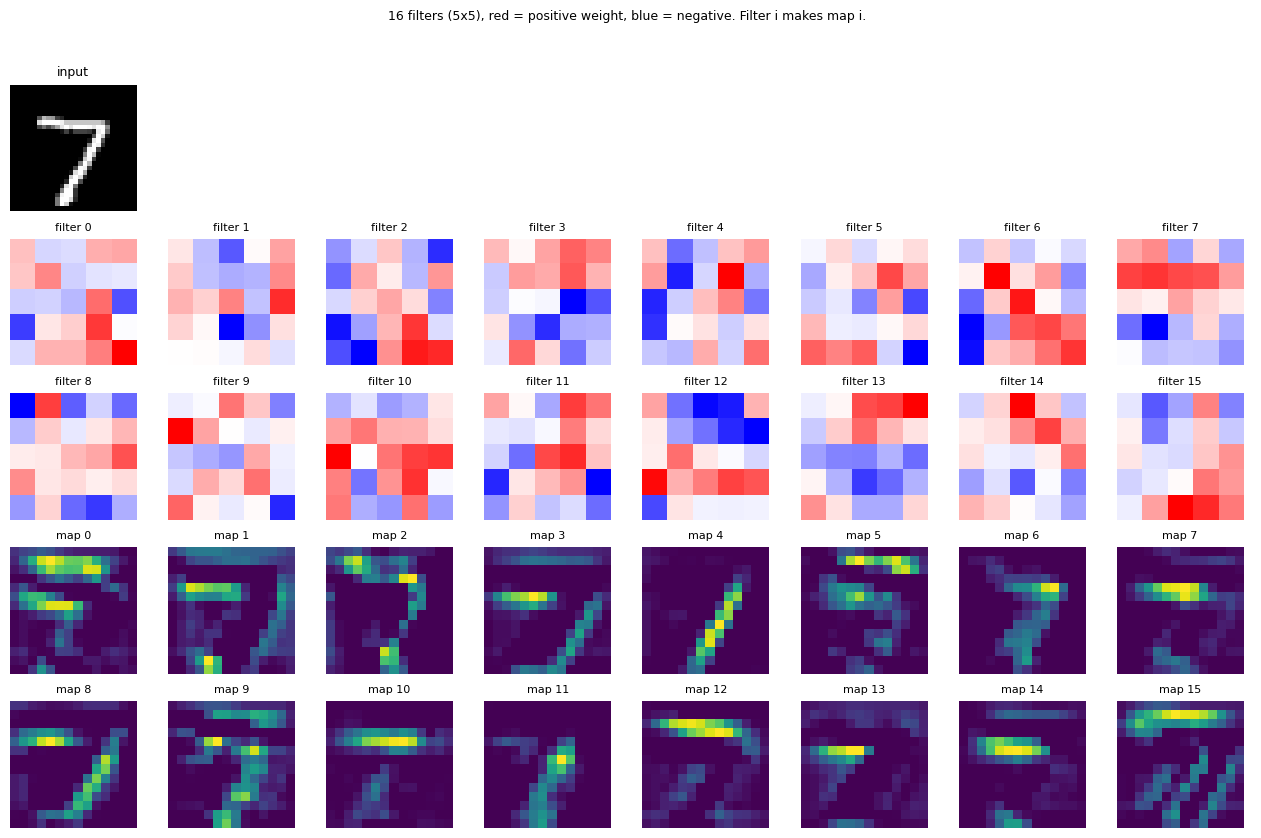

In [8]:
# The second conv layer works too (its filters are averaged over their 8 input maps):
_ = show_filters_and_feature_maps(cnn, x_test[0], conv_layer=cnn.conv2)

# On your skorch homework model, pass the trained net and one image scaled the way you trained it:
# show_filters_and_feature_maps(net, X_test[0])

## Part 2: Feedback alignment (FA)

**Backprop recap.** After the forward pass, the error at the output travels backward one layer at a time. To pass the error down a layer, backprop multiplies it by **the same weights W that layer used going forward**.

**The problem.** In a brain, the backward signal would travel through *different* synapses. Those synapses would need to copy the exact strengths of the forward ones. That is the **weight transport problem** from the Lillicrap paper.

**FA's idea.** Send the error back through a **fixed random matrix B** instead of W. B is picked once at the start and never changes. Everything else (the forward pass, the loss, how each layer updates its own weights) stays exactly the same.

```
forward:    input  --- W --->  output
backward:   error  <--- ? ---  error from the layer above

            backprop: ? = W          FA: ? = B  (random, fixed)
```

**Your job:** fill in the one line in `backward` that makes this happen. Then run the check below it.

In [9]:
class FALinearFunction(torch.autograd.Function):
    """The math of a linear layer that learns with feedback alignment.

    forward:  output = input @ W.T + b      (exactly like nn.Linear)
    backward: sends the error down to the layer below.
              Backprop sends it through W. FA sends it through B.
    """

    @staticmethod
    def forward(ctx, input, W, b, B):
        ctx.save_for_backward(input, W, B)
        return input @ W.T + b

    @staticmethod
    def backward(ctx, grad_output):
        # grad_output: the error arriving from the layer above, shape (batch, out_features)
        input, W, B = ctx.saved_tensors

        # Error to send to the layer below, shape (batch, in_features).
        # Backprop would write:   grad_input = grad_output @ W
        # ---------------- YOUR CODE: one line ----------------
        grad_input = grad_output @ B   # <- replace None with FA's version
        # ------------------------------------------------------
        if grad_input is None:
            raise NotImplementedError('Fill in grad_input in FALinearFunction.backward (see the hint above it).')

        # How this layer's OWN weights should change. Same as backprop: FA only changes
        # what gets sent backward to the layer below, not how a layer updates itself.
        grad_W = grad_output.T @ input
        grad_b = grad_output.sum(dim=0)
        return grad_input, grad_W, grad_b, None   # None: B is never trained


class FALinear(nn.Module):
    """Drop-in replacement for nn.Linear that learns with feedback alignment."""

    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(out_features, in_features))  # W: learned
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.register_buffer('B', torch.empty(out_features, in_features))  # B: random, fixed forever
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))  # same starting scale as nn.Linear
        nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))

    def forward(self, x):
        return FALinearFunction.apply(x, self.weight, self.bias, self.B)

    def extra_repr(self):
        return f'in_features={self.weight.shape[1]}, out_features={self.weight.shape[0]}'

In [10]:
def check_fa_layer():
    torch.manual_seed(0)
    x = torch.randn(5, 7, requires_grad=True)   # a batch of 5 inputs with 7 features
    W, b, B = torch.randn(3, 7), torch.randn(3), torch.randn(3, 7)
    g = torch.randn(5, 3)                        # pretend error arriving from the layer above
    try:
        FALinearFunction.apply(x, W, b, B).backward(g)
    except NotImplementedError:
        print('Not filled in yet: replace None in FALinearFunction.backward.')
        return False
    except RuntimeError as e:
        print('The shapes do not line up. grad_input must have the same shape as the input: (batch, in_features).')
        print('PyTorch said:', e)
        return False
    if torch.allclose(x.grad, g @ W):
        print('Close! That is backprop: the error went back through W. FA sends it back through B instead.')
        return False
    if torch.allclose(x.grad, g @ B):
        print('PASS: the error now travels backward through the fixed random matrix B.')
        return True
    print('Not quite. Hint: backprop would be  grad_output @ W.')
    return False

fa_ready = check_fa_layer()

PASS: the error now travels backward through the fixed random matrix B.


### Predict first
Before you train: **will FA learn MNIST at all? How close to backprop will it get?** Post your guess in the Discord thread.

In [11]:
def make_mlp(rule, hidden=(256, 256)):
    """A small MLP. rule='bp' uses normal layers; rule='fa' uses feedback-alignment layers."""
    Layer = nn.Linear if rule == 'bp' else FALinear
    layers, width = [nn.Flatten()], 28 * 28
    for h in hidden:
        layers += [Layer(width, h), nn.ReLU()]
        width = h
    layers.append(Layer(width, 10))
    return nn.Sequential(*layers)

print(make_mlp('fa'))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): FALinear(in_features=784, out_features=256)
  (2): ReLU()
  (3): FALinear(in_features=256, out_features=256)
  (4): ReLU()
  (5): FALinear(in_features=256, out_features=10)
)


In [12]:
assert fa_ready, 'Run check_fa_layer() and get a PASS first.'

torch.manual_seed(0)
bp_model = make_mlp('bp')
print('Backprop:')
bp_history = train(bp_model, epochs=3)

torch.manual_seed(0)
fa_model = make_mlp('fa')
print('Feedback alignment:')
fa_history = train(fa_model, epochs=3)

Backprop:
epoch 1: test accuracy 95.53%
epoch 2: test accuracy 96.83%
epoch 3: test accuracy 97.71%
Feedback alignment:
epoch 1: test accuracy 93.82%
epoch 2: test accuracy 95.07%
epoch 3: test accuracy 95.58%


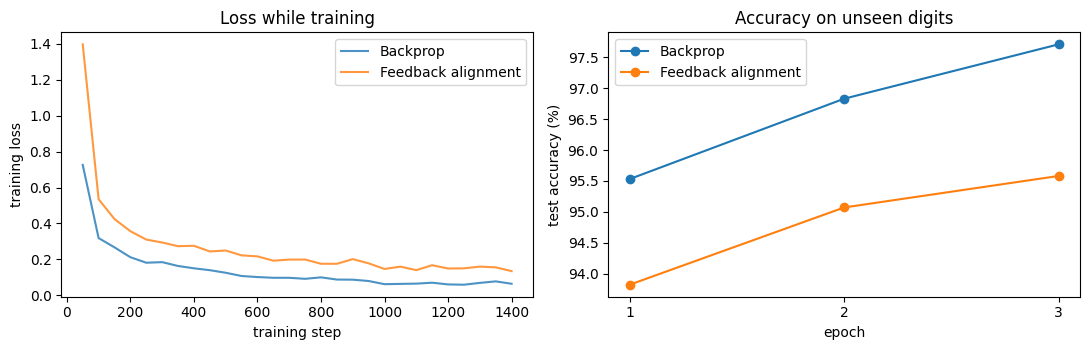

Final test accuracy  BP: 97.71%   FA: 95.58%


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(bp_history['step'], bp_history['loss'], label='Backprop', alpha=0.8)
ax[0].plot(fa_history['step'], fa_history['loss'], label='Feedback alignment', alpha=0.8)
ax[0].set_xlabel('training step'); ax[0].set_ylabel('training loss'); ax[0].set_title('Loss while training'); ax[0].legend()
epochs = range(1, len(bp_history['test_acc']) + 1)
ax[1].plot(epochs, [a * 100 for a in bp_history['test_acc']], 'o-', label='Backprop')
ax[1].plot(epochs, [a * 100 for a in fa_history['test_acc']], 'o-', label='Feedback alignment')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('test accuracy (%)'); ax[1].set_title('Accuracy on unseen digits')
ax[1].set_xticks(list(epochs)); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Final test accuracy  BP: {bp_history['test_acc'][-1]:.2%}   FA: {fa_history['test_acc'][-1]:.2%}")

## Part 3: The FA race

Train the most accurate **FA** network. Change anything in `CONFIG`, run the cell, and post the printed **LEADERBOARD** line in the Discord thread.

**Rules**
- It must be FA (`make_mlp('fa', ...)`), and your check must have passed.
- At most **3 epochs**.
- Each hidden layer has at most **1024** units.
- Don't edit `FALinear` or the test set.

**Knobs:** `hidden` (how many layers, how wide), `lr` (learning rate), `optimizer` (`'adam'` or `'sgd'`), `batch_size`, `epochs`.

In [14]:
TEAM = 'your names here'
CONFIG = dict(hidden=(1024,), lr=5e-4, optimizer='adam', batch_size=88, epochs=3)

assert fa_ready, 'Get a PASS from check_fa_layer() first.'
assert CONFIG['epochs'] <= 3, 'Max 3 epochs.'
assert all(h <= 1024 for h in CONFIG['hidden']), 'Max 1024 units per hidden layer.'

torch.manual_seed(0)
race_model = make_mlp('fa', CONFIG['hidden'])
race_history = train(race_model, epochs=CONFIG['epochs'], lr=CONFIG['lr'],
                     optimizer=CONFIG['optimizer'], batch_size=CONFIG['batch_size'])
print(f"LEADERBOARD | {TEAM} | FA test accuracy {race_history['test_acc'][-1]:.2%} | {CONFIG}")

epoch 1: test accuracy 95.29%
epoch 2: test accuracy 96.88%
epoch 3: test accuracy 97.43%
LEADERBOARD | your names here | FA test accuracy 97.43% | {'hidden': (1024,), 'lr': 0.0005, 'optimizer': 'adam', 'batch_size': 88, 'epochs': 3}


## Bonus (fast teams): watch the alignment happen

FA works because the forward weights slowly come to agree with the random feedback B. We can measure this. Compute the **angle** between the error FA sends to the last hidden layer and the error backprop *would* have sent. 90° means unrelated, and 0° means identical.

epoch 1: test accuracy 93.82%
epoch 2: test accuracy 95.07%
epoch 3: test accuracy 95.58%


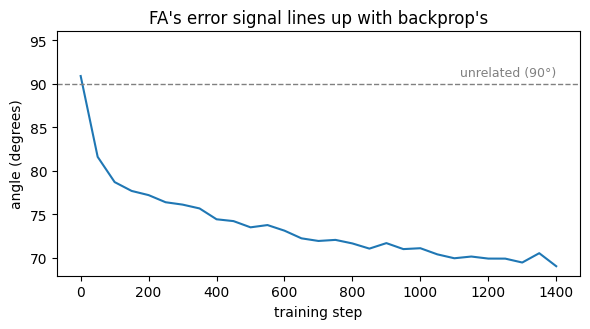

angle at start: 91°   at end: 69°


In [15]:
def alignment_angle(model, x, y):
    """Angle (degrees) between FA's error signal for the last hidden layer and backprop's."""
    last = model[-1]
    with torch.no_grad():
        delta = torch.softmax(model(x), dim=1) - F.one_hot(y, 10).float()   # error at the output
        fa_signal = (delta @ last.B).flatten()        # what FA sends down
        bp_signal = (delta @ last.weight).flatten()   # what backprop would send down
        cos = fa_signal @ bp_signal / (fa_signal.norm() * bp_signal.norm())
    return torch.rad2deg(torch.acos(cos.clamp(-1, 1))).item()

torch.manual_seed(0)
probe = make_mlp('fa').to(device)
xs, ys = x_test[:1000], y_test[:1000]
angles = [(0, alignment_angle(probe, xs, ys))]
train(probe, epochs=3, callback=lambda step: angles.append((step, alignment_angle(probe, xs, ys))))

plt.figure(figsize=(6, 3.4))
plt.plot(*zip(*angles))
plt.axhline(90, ls='--', c='gray', lw=1)
plt.text(angles[-1][0], 90.5, 'unrelated (90°)', color='gray', fontsize=9, ha='right', va='bottom')
plt.ylim(top=96)
plt.xlabel('training step'); plt.ylabel('angle (degrees)')
plt.title("FA's error signal lines up with backprop's")
plt.tight_layout(); plt.show()
print(f'angle at start: {angles[0][1]:.0f}°   at end: {angles[-1][1]:.0f}°')

## Wrap-up
1. Did FA learn? How far behind backprop was it?
2. FA fixes one of the three problems from the Lillicrap paper. Which one, and which two are left?
3. **Next week:** FA inside a CNN, and how we tell whether a network is brain-like.